<a href="https://colab.research.google.com/github/pedrosampaiom2007-gif/Analise-de-dados-Airbnb-Albany/blob/main/notebooks/analise_precos_airbnb_albany.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quanto custa uma noite em Albany? Análise de preços do Airbnb

Análise dos anúncios do Airbnb em Albany, capital do estado de Nova York (EUA), com Python e pandas: limpeza dos dados, tratamento de outliers e respostas para 6 perguntas.

**Fonte:** [Inside Airbnb](https://insideairbnb.com/get-the-data/), Albany (CC BY 4.0). Os preços da base estão em dólar (US$). Os bairros de Albany são divididos em *wards* (distritos).

## Perguntas
1. Quais são os bairros mais caros e os mais baratos?
2. Quanto custa cada tipo de acomodação nos bairros com mais anúncios?
3. Superhosts cobram mais e são mais bem avaliados?
4. Quais são as comodidades mais comuns? Ter piscina deixa a diária mais cara?
5. Quantos anfitriões entraram no Airbnb a cada ano?
6. Quanto custa a diária média em reais?

## Sumário
0. Configuração
1. Coleta dos dados
2. Entendimento inicial
3. Tratamento
4. Outliers
5. Transformações
6. Análises
7. Exportação
8. Conclusões

## 0. Configuração

In [5]:
# Importa as bibliotecas usadas no projeto.
# Por quê: pandas/numpy para tratar os dados, matplotlib/seaborn para os gráficos, requests para a API do Banco Central.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

# Mostra todas as colunas ao exibir um DataFrame (a base tem mais de 70 colunas).
pd.set_option('display.max_columns', None)

## 1. Coleta dos dados

Arquivo `listings.csv` (anúncios) de Albany, baixado do Inside Airbnb e enviado ao Colab.

In [6]:
# Arquivo listings de Albany (insideairbnb.com/get-the-data), enviado para o Colab
URL_LISTINGS = '/content/listings.csv'

In [7]:
# Colunas usadas na análise (as outras 60+ não são necessárias).
COLUNAS = [
    'id', 'name', 'host_id', 'host_since', 'host_response_rate', 'host_acceptance_rate',
    'host_is_superhost', 'host_identity_verified', 'host_listings_count',
    'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type', 'room_type',
    'accommodates', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
    'minimum_nights', 'availability_365', 'number_of_reviews', 'first_review', 'last_review',
    'review_scores_rating', 'review_scores_location', 'review_scores_value', 'instant_bookable',
]

## 2. Entendimento inicial

Antes de mexer nos dados: quantas linhas, quais tipos, onde estão os nulos.

In [8]:
df=pd.read_csv(URL_LISTINGS,usecols=COLUNAS,sep=',')# lendo o arquivo

In [9]:
df.head() # Conhecendo a base de dados

,id,name,host_id,host_since,host_response_rate,host_acceptance_rate,host_is_superhost,host_listings_count,host_identity_verified,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,availability_365,number_of_reviews,first_review,last_review,review_scores_rating,review_scores_location,review_scores_value,instant_bookable
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,f,1,t,THIRD WARD,42.65789,-73.75370,Entire rental unit,Entire home/apt,4,1 bath,2,2.0,"[""Essentials"", ""Smoke alarm"", ""Carbon monoxide...",$65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
1,3820211,Restored Precinct in Center Sq. w/Parking,19648678,NaN,NaN,NaN,t,7,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,3,1 bath,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",$171.00,1.0,342,320,2014-08-15,2026-09-07,4.75,4.81,4.78,NaN
2,6623339,Center Sq. Loft in Converted Precinct w/ Parking,19648678,NaN,NaN,NaN,t,7,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,2,1 bath,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",$242.00,1.0,337,344,2015-06-07,2026-09-07,4.74,4.79,4.73,NaN
3,9501054,Spacious suite with full bath by Capital Center,29288920,NaN,NaN,NaN,f,2,t,SECOND WARD,42.64734,-73.75851,Private room in rental unit,Private room,2,1 private bath,1,2.0,"[""Smart lock"", ""Microwave"", ""Window AC unit"", ...",$79.00,1.0,250,479,2016-02-02,2026-09-04,4.59,4.77,4.68,NaN
4,10768745,Alb hospital area studio bath wifi. (Red),5691268,NaN,NaN,NaN,t,2,t,FOURTEENTH WARD,42.66078,-73.80553,Private room in guest suite,Private room,1,1 private bath,1,1.0,"[""Microwave"", ""Window AC unit"", ""Hangers"", ""Ca...",$50.00,1.0,142,941,2016-02-05,2026-08-30,4.84,4.93,4.91,NaN


In [10]:
df.shape # Linhas x colunas

(500, 29)

In [11]:
# Renomeando as colunas para o português

colunas_traduzidas = {
    'id': 'id',
    'name': 'nome',
    'host_id': 'anfitriao_id',
    'host_since': 'anfitriao_desde',
    'host_response_rate': 'taxa_resposta_anfitriao',
    'host_acceptance_rate': 'taxa_aceitacao_anfitriao',
    'host_is_superhost': 'anfitriao_superhost',
    'host_identity_verified': 'anfitriao_identidade_verificada',
    'host_listings_count': 'total_anuncios_anfitriao',
    'neighbourhood_cleansed': 'bairro',
    'latitude': 'latitude',
    'longitude': 'longitude',
    'property_type': 'tipo_propriedade',
    'room_type': 'tipo_quarto',
    'accommodates': 'acomoda',
    'bathrooms_text': 'banheiros_texto',
    'bedrooms': 'quartos',
    'beds': 'camas',
    'amenities': 'comodidades',
    'price': 'preco',
    'minimum_nights': 'minimo_noites',
    'availability_365': 'disponibilidade_365',
    'number_of_reviews': 'numero_avaliacoes',
    'first_review': 'primeira_avaliacao',
    'last_review': 'ultima_avaliacao',
    'review_scores_rating': 'nota_geral',
    'review_scores_location': 'nota_localizacao',
    'review_scores_value': 'nota_custo_beneficio',
    'instant_bookable': 'reserva_instantanea'
}

df.rename(columns=colunas_traduzidas, inplace=True)
display(df.head())

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,2992450,Luxury 2 bedroom apartment,4621559,NaN,NaN,NaN,f,1,t,THIRD WARD,42.65789,-73.75370,Entire rental unit,Entire home/apt,4,1 bath,2,2.0,"[""Essentials"", ""Smoke alarm"", ""Carbon monoxide...",$65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
1,3820211,Restored Precinct in Center Sq. w/Parking,19648678,NaN,NaN,NaN,t,7,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,3,1 bath,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",$171.00,1.0,342,320,2014-08-15,2026-09-07,4.75,4.81,4.78,NaN
2,6623339,Center Sq. Loft in Converted Precinct w/ Parking,19648678,NaN,NaN,NaN,t,7,t,SIXTH WARD,42.65222,-73.76724,Entire rental unit,Entire home/apt,2,1 bath,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",$242.00,1.0,337,344,2015-06-07,2026-09-07,4.74,4.79,4.73,NaN
3,9501054,Spacious suite with full bath by Capital Center,29288920,NaN,NaN,NaN,f,2,t,SECOND WARD,42.64734,-73.75851,Private room in rental unit,Private room,2,1 private bath,1,2.0,"[""Smart lock"", ""Microwave"", ""Window AC unit"", ...",$79.00,1.0,250,479,2016-02-02,2026-09-04,4.59,4.77,4.68,NaN
4,10768745,Alb hospital area studio bath wifi. (Red),5691268,NaN,NaN,NaN,t,2,t,FOURTEENTH WARD,42.66078,-73.80553,Private room in guest suite,Private room,1,1 private bath,1,1.0,"[""Microwave"", ""Window AC unit"", ""Hangers"", ""Ca...",$50.00,1.0,142,941,2016-02-05,2026-08-30,4.84,4.93,4.91,NaN


In [12]:
df.info()# Conhecendo os tipos de dados

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 29 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id                               500 non-null    int64  
 1   nome                             500 non-null    object 
 2   anfitriao_id                     500 non-null    int64  
 3   anfitriao_desde                  0 non-null      float64
 4   taxa_resposta_anfitriao          0 non-null      float64
 5   taxa_aceitacao_anfitriao         0 non-null      float64
 6   anfitriao_superhost              500 non-null    object 
 7   total_anuncios_anfitriao         500 non-null    int64  
 8   anfitriao_identidade_verificada  500 non-null    object 
 9   bairro                           500 non-null    object 
 10  latitude                         500 non-null    float64
 11  longitude                        500 non-null    float64
 12  tipo_propriedade      

In [13]:
df.isna().sum().sum()# Identificando quantos valores nulos há

np.int64(2296)

In [14]:
# Salvando em uma variável os dados nulos
df_nulos=df.isna().stack()

In [15]:
# Aplicando a máscara, ou seja, filtrando o resultado do outro filtro
df_nulos = df_nulos[df_nulos]


In [16]:
# Listando a localização dos dados nulos pelo índice
lista_nul = df_nulos.index.to_list()


## 3. Tratamento

Em cada etapa que remove linhas, mostrar quantas linhas existiam antes e depois.

### 3.1 Duplicadas

In [17]:
df.duplicated().sum() # Nossa base de dados não possui duplicatas, portanto não há o que remover

np.int64(0)

In [18]:
# O id é único por anúncio, então também checamos o mesmo imóvel cadastrado mais de uma vez
# (mesmo anfitrião, nome e localização)
df.duplicated(subset=['anfitriao_id', 'nome', 'latitude', 'longitude']).sum()

# Nenhuma duplicata encontrada; nada foi removido.

np.int64(0)

### 3.2 Preço
O preço vem como texto: `"$1,234.00"`. É preciso remover `$` e `,` e converter para float.

In [19]:
df['preco']

,preco
0,$65.73
1,$171.00
2,$242.00
3,$79.00
4,$50.00
...,...
495,$197.00
496,$185.00
497,$139.20
498,$356.00


In [20]:
df['preco']=df['preco'].str.replace('$','',regex=False).str.replace(',','',regex=False)

In [21]:
df['preco']=df['preco'].astype(float)

### 3.3 Percentuais
`"95%"` vira `0.95`.

In [22]:
# As taxas vêm como texto ("95%"): tiramos o '%', convertemos para número e dividimos por 100
colunas_taxa = ['taxa_resposta_anfitriao', 'taxa_aceitacao_anfitriao']

for coluna in colunas_taxa:
    df[coluna] = df[coluna].replace('N/A', np.nan)
    df[coluna] = df[coluna].astype(str).str.replace('%', '', regex=False).astype(float) / 100

In [23]:
df[colunas_taxa].describe() # Conferindo: os valores devem estar entre 0 e 1

,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao
count,0.0,0.0
mean,NaN,NaN
std,NaN,NaN
min,NaN,NaN
25%,NaN,NaN
50%,NaN,NaN
75%,NaN,NaN
max,NaN,NaN


### 3.4 Colunas t/f

In [24]:
mapeamento_de_cols={

                    't':True,
                    'f':False}

In [25]:
# Os valores 't' e 'f' viram True e False nas três colunas de sim/não, para facilitar o tratamento e a leitura
colunas_tf = ['anfitriao_superhost', 'anfitriao_identidade_verificada', 'reserva_instantanea']
df[colunas_tf] = df[colunas_tf].replace(mapeamento_de_cols)

/tmp/ipykernel_2203/1929713303.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[colunas_tf] = df[colunas_tf].replace(mapeamento_de_cols)


In [26]:
df[colunas_tf].head() # Visualizando a alteração dos dados

,anfitriao_superhost,anfitriao_identidade_verificada,reserva_instantanea
0,False,True,NaN
1,True,True,NaN
2,True,True,NaN
3,False,True,NaN
4,True,True,NaN


### 3.5 Datas

In [27]:
datas_null=df[['primeira_avaliacao','ultima_avaliacao']]


In [28]:
df_aval=df[(df['primeira_avaliacao'].isna()) & (df['ultima_avaliacao'].isna())]

In [29]:
# Anúncios sem nenhuma avaliação não têm notas, então não servem para as análises de avaliação: removemos
print('Linhas antes:', len(df))
df = df.drop(index=df_aval.index)
print('Linhas depois:', len(df))

# Convertendo as colunas de data de texto para datetime
df['anfitriao_desde'] = pd.to_datetime(df['anfitriao_desde'])
df['primeira_avaliacao'] = pd.to_datetime(df['primeira_avaliacao'])
df['ultima_avaliacao'] = pd.to_datetime(df['ultima_avaliacao'])

Linhas antes: 500
Linhas depois: 449


In [30]:
df[['anfitriao_desde', 'primeira_avaliacao', 'ultima_avaliacao']].info()  # agora devem ser datetime64

<class 'pandas.core.frame.DataFrame'>
Index: 449 entries, 0 to 497
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   anfitriao_desde     0 non-null      datetime64[ns]
 1   primeira_avaliacao  449 non-null    datetime64[ns]
 2   ultima_avaliacao    449 non-null    datetime64[ns]
dtypes: datetime64[ns](3)
memory usage: 14.0 KB


### 3.6 Banheiros
`"1.5 baths"` vira `1.5`.

In [31]:
# Substituindo 'Half-bath' por '0.5' para que possa ser convertido em número
df['banheiros_texto'] = df['banheiros_texto'].str.replace('(?i)half-bath', '0.5', regex=True)

# Extraindo apenas os números (ponto flutuante ou inteiros) ignorando textos e espaços
df['banheiros_texto'] = df['banheiros_texto'].str.extract(r'(\d+\.?\d*)')[0]

# Convertendo a coluna para tipo numérico correto (float) para aceitar valores decimais (ex: 1.5)
df['banheiros_texto'] = df['banheiros_texto'].astype(float)

# Visualizando o resultado
df['banheiros_texto'].head()

,banheiros_texto
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0


### 3.7 Nulos nas avaliações
Anúncios sem nenhuma avaliação têm `review_scores_*` nulos. *(decisão e justificativa)*

In [32]:
df

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.657890,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,"[""Essentials"", ""Smoke alarm"", ""Carbon monoxide...",65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
1,3820211,Restored Precinct in Center Sq. w/Parking,19648678,NaT,NaN,NaN,True,7,True,SIXTH WARD,42.652220,-73.767240,Entire rental unit,Entire home/apt,3,1.0,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",171.00,1.0,342,320,2014-08-15,2026-09-07,4.75,4.81,4.78,NaN
2,6623339,Center Sq. Loft in Converted Precinct w/ Parking,19648678,NaT,NaN,NaN,True,7,True,SIXTH WARD,42.652220,-73.767240,Entire rental unit,Entire home/apt,2,1.0,1,1.0,"[""Smart lock"", ""Microwave"", ""Conditioner"", ""Ki...",242.00,1.0,337,344,2015-06-07,2026-09-07,4.74,4.79,4.73,NaN
3,9501054,Spacious suite with full bath by Capital Center,29288920,NaT,NaN,NaN,False,2,True,SECOND WARD,42.647340,-73.758510,Private room in rental unit,Private room,2,1.0,1,2.0,"[""Smart lock"", ""Microwave"", ""Window AC unit"", ...",79.00,1.0,250,479,2016-02-02,2026-09-04,4.59,4.77,4.68,NaN
4,10768745,Alb hospital area studio bath wifi. (Red),5691268,NaT,NaN,NaN,True,2,True,FOURTEENTH WARD,42.660780,-73.805530,Private room in guest suite,Private room,1,1.0,1,1.0,"[""Microwave"", ""Window AC unit"", ""Hangers"", ""Ca...",50.00,1.0,142,941,2016-02-05,2026-08-30,4.84,4.93,4.91,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
484,1741324771709453688,Serenity; a stylish 2-bedroom retreat near Ual...,252422913,NaT,NaN,NaN,True,2,True,FIFTEENTH WARD,42.670039,-73.824769,Entire townhouse,Entire home/apt,4,2.0,2,2.0,"[""Blender"", ""Outdoor dining area"", ""Microwave""...",185.00,3.0,339,1,2026-08-22,2026-08-22,5.00,5.00,4.00,NaN
485,1742918869669999734,Albany Stay Breakfast included minutes to Down...,466790114,NaT,NaN,NaN,False,44,True,ELEVENTH WARD,42.674830,-73.783527,Entire rental unit,Entire home/apt,2,1.0,1,1.0,"[""TV"", ""Hangers"", ""Smoke alarm"", ""Hot water"", ...",112.00,1.0,352,1,2026-08-31,2026-08-31,5.00,5.00,5.00,NaN
486,1742925361910695495,Central Albany Room Next to downtown W/Breakfast,466790114,NaT,NaN,NaN,False,44,True,ELEVENTH WARD,42.680549,-73.783583,Entire rental unit,Entire home/apt,2,1.0,1,1.0,"[""TV"", ""Hangers"", ""Smoke alarm"", ""Hot water"", ...",102.00,1.0,363,1,2026-08-07,2026-08-07,5.00,5.00,5.00,NaN
494,1761681531692933226,"Albany Value Stay Near universities, Hospitals",1761681400986126720,NaT,NaN,NaN,False,1,True,TENTH WARD,42.661820,-73.790141,Entire home,Entire home/apt,7,1.5,4,5.0,"[""Smart lock"", ""Kitchen"", ""Pets allowed"", ""TV""...",289.00,2.0,259,2,2026-09-04,2026-09-07,5.00,5.00,5.00,NaN


In [33]:
print('Linhas antes:', len(df))
df = df.dropna(subset=['nota_geral', 'nota_localizacao', 'nota_custo_beneficio'])
print('Linhas depois:', len(df))
# Foi decidido remover as linhas com scores = NaN, pois sem avaliações não há resultados; é desnecessário manter esse tipo de dado na nossa base

Linhas antes: 449
Linhas depois: 449


## 4. Outliers de preço

In [34]:
# Tamanho da base antes de remover os outliers
print('Linhas antes:', len(df))

Linhas antes: 449


In [35]:
q1=df['preco'].quantile(0.25)
q3=df['preco'].quantile(0.75)
IQR=q3-q1

limite_superior= q3+1.5*IQR
limite_inferior=q1-1.5*IQR

# Identificando os outliers
outliers= (df['preco']>limite_superior) | (df['preco']<limite_inferior)

In [36]:
df.drop(index=outliers[outliers].index, inplace=True)
print('Linhas depois:', len(df))

Linhas depois: 432


In [37]:
outliers.sum() # Quantidade de anúncios removidos como outliers

np.int64(17)

**Decisão sobre os outliers:** os anúncios com preço fora dos limites do IQR foram removidos. Preços extremos distorcem a média e não representam a hospedagem típica, que é o que a análise quer mostrar.

## 5. Transformações

### 5.1 Comodidades
`'["Wifi", "TV", "Kitchen"]'` é uma string, não uma lista.

In [38]:
# Transformamos em lista as comodidades e usamos o explode pra quebrar essas listas e fazê-las virar linhas
import ast

# Usando ast.literal_eval mapeado na coluna para reconstruir as listas com segurança
df['comodidades'] = df['comodidades'].map(ast.literal_eval)

# Agora aplicamos o explode para expandir as comodidades em novas linhas
df_explodido = df.explode('comodidades')
df_explodido

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Essentials,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
0,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Smoke alarm,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
0,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Carbon monoxide alarm,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
0,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Kitchen,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
0,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Wifi,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
497,1766631627977800990,Center Square Beauty,117669789,NaT,NaN,NaN,False,1,True,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Stove,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
497,1766631627977800990,Center Square Beauty,117669789,NaT,NaN,NaN,False,1,True,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Wifi,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
497,1766631627977800990,Center Square Beauty,117669789,NaT,NaN,NaN,False,1,True,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Washer,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
497,1766631627977800990,Center Square Beauty,117669789,NaT,NaN,NaN,False,1,True,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Freezer,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN


In [39]:
df_explodido.reset_index(inplace=True)

In [40]:
df_explodido.drop(columns='index', inplace=True)

In [41]:
df_explodido

,id,nome,anfitriao_id,anfitriao_desde,taxa_resposta_anfitriao,taxa_aceitacao_anfitriao,anfitriao_superhost,total_anuncios_anfitriao,anfitriao_identidade_verificada,bairro,latitude,longitude,tipo_propriedade,tipo_quarto,acomoda,banheiros_texto,quartos,camas,comodidades,preco,minimo_noites,disponibilidade_365,numero_avaliacoes,primeira_avaliacao,ultima_avaliacao,nota_geral,nota_localizacao,nota_custo_beneficio,reserva_instantanea
0,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Essentials,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
1,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Smoke alarm,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
2,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Carbon monoxide alarm,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
3,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Kitchen,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
4,2992450,Luxury 2 bedroom apartment,4621559,NaT,NaN,NaN,False,1,True,THIRD WARD,42.65789,-73.753700,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Wifi,65.73,28.0,169,9,2014-07-01,2022-08-17,3.56,3.22,3.67,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16414,1766631627977800990,Center Square Beauty,117669789,NaT,NaN,NaN,False,1,True,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Stove,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
16415,1766631627977800990,Center Square Beauty,117669789,NaT,NaN,NaN,False,1,True,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Wifi,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
16416,1766631627977800990,Center Square Beauty,117669789,NaT,NaN,NaN,False,1,True,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Washer,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN
16417,1766631627977800990,Center Square Beauty,117669789,NaT,NaN,NaN,False,1,True,SIXTH WARD,42.65219,-73.765701,Entire rental unit,Entire home/apt,4,1.0,2,2.0,Freezer,139.20,1.0,156,2,2026-09-07,2026-09-13,5.00,5.00,5.00,NaN


### 5.2 Ano de entrada do anfitrião
Nova coluna com o ano de `host_since`.

In [42]:
df['anfitriao_desde'].isna().sum()
# Se algum anfitrião estiver sem data de entrada, usamos a data da primeira avaliação como aproximação

np.int64(432)

In [43]:
df['anfitriao_desde'] = df['anfitriao_desde'].fillna(df['primeira_avaliacao'])

### 5.3 Conferência final do tratamento
Tipos e nulos depois de todas as etapas.

In [44]:
df.info() # Conferindo os tipos e os nulos depois de todas as etapas de tratamento

<class 'pandas.core.frame.DataFrame'>
Index: 432 entries, 0 to 497
Data columns (total 29 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   id                               432 non-null    int64         
 1   nome                             432 non-null    object        
 2   anfitriao_id                     432 non-null    int64         
 3   anfitriao_desde                  432 non-null    datetime64[ns]
 4   taxa_resposta_anfitriao          0 non-null      float64       
 5   taxa_aceitacao_anfitriao         0 non-null      float64       
 6   anfitriao_superhost              432 non-null    bool          
 7   total_anuncios_anfitriao         432 non-null    int64         
 8   anfitriao_identidade_verificada  432 non-null    bool          
 9   bairro                           432 non-null    object        
 10  latitude                         432 non-null    float64       
 11

## 6. Análises

### P1. Os 5 bairros mais caros e os 5 mais baratos
Preço médio por noite (já sem os outliers), considerando só bairros com pelo menos 10 anúncios, para não comparar bairros com poucos casos.

In [45]:
# Só entram bairros com pelo menos 10 anúncios (Albany tem poucos anúncios por bairro)
anuncios_por_bairro = df['bairro'].value_counts()
bairros_validos = anuncios_por_bairro[anuncios_por_bairro >= 10].index

# Preço médio de cada bairro, do maior para o menor
preco_bairro = df[df['bairro'].isin(bairros_validos)].groupby('bairro')['preco'].mean().sort_values(ascending=False)

# Top 5 bairros mais caros
caros = preco_bairro.head(5)
caros

,preco
bairro,
EIGHTH WARD,258.226667
FIFTEENTH WARD,228.314667
FOURTH WARD,203.714286
SEVENTH WARD,187.718333
SECOND WARD,186.595526


In [46]:
# Top 5 bairros mais baratos
baratos = preco_bairro.tail(5).sort_values()
baratos

,preco
bairro,
ELEVENTH WARD,102.330606
THIRTEENTH WARD,128.360256
TENTH WARD,140.359750
NINTH WARD,141.848462
THIRD WARD,145.605000


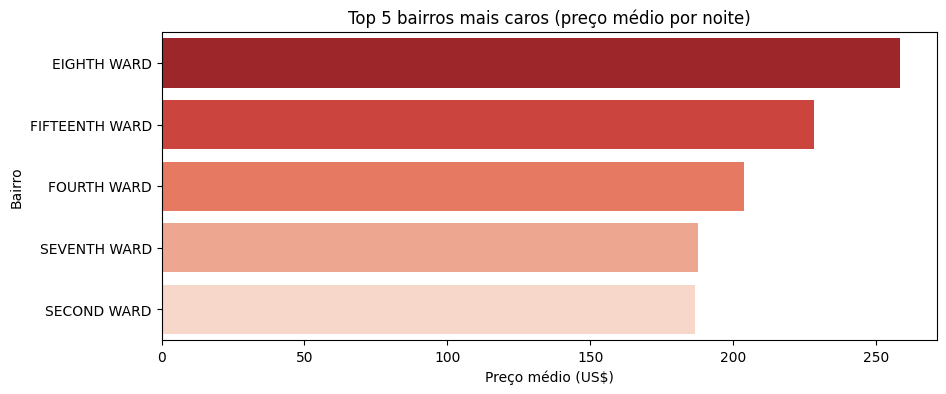

In [47]:
# Gráfico dos 5 bairros mais caros
plt.figure(figsize=(10, 4))
sns.barplot(x=caros.values, y=caros.index, hue=caros.index, palette='Reds_r', legend=False)
plt.title('Top 5 bairros mais caros (preço médio por noite)')
plt.xlabel('Preço médio (US$)')
plt.ylabel('Bairro')
plt.show()

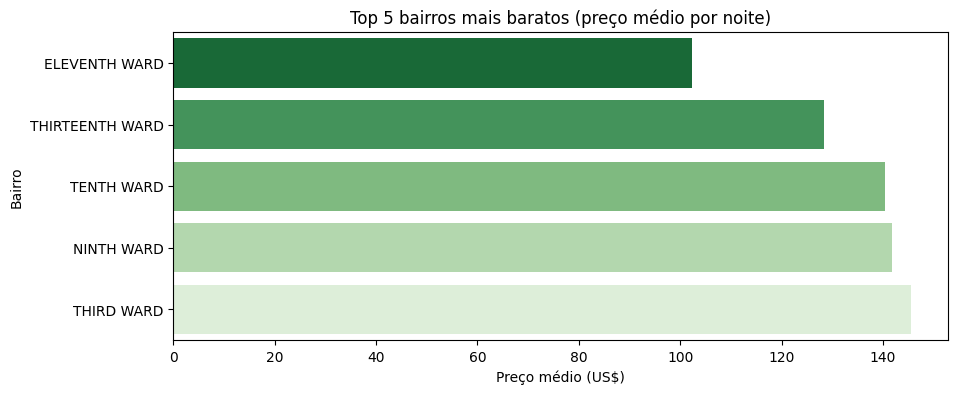

In [48]:
# Gráfico dos 5 bairros mais baratos
plt.figure(figsize=(10, 4))
sns.barplot(x=baratos.values, y=baratos.index, hue=baratos.index, palette='Greens_r', legend=False)
plt.title('Top 5 bairros mais baratos (preço médio por noite)')
plt.xlabel('Preço médio (US$)')
plt.ylabel('Bairro')
plt.show()

**Leitura dos gráficos:** *(completar com os resultados)*

### P2. Preço por tipo de acomodação nos 5 bairros com mais anúncios

In [49]:
# Os 5 bairros com mais anúncios
top_bairros = df['bairro'].value_counts().head(5).index

# Preço médio de cada tipo de acomodação (linhas: bairros, colunas: tipos)
df[df['bairro'].isin(top_bairros)].pivot_table(index='bairro', columns='tipo_quarto', values='preco', aggfunc='mean').round(2)

tipo_quarto,Entire home/apt,Private room
bairro,,
NINTH WARD,193.71,101.78
SECOND WARD,198.40,86.25
SIXTH WARD,162.86,115.04
TENTH WARD,210.56,88.47
THIRTEENTH WARD,191.75,79.38


### P3. Superhosts cobram mais e têm avaliações melhores?

In [50]:
# Comparação de preço médio e nota geral média entre Superhosts e não-Superhosts
df.groupby('anfitriao_superhost')[['preco', 'nota_geral']].mean().round(2)

,preco,nota_geral
anfitriao_superhost,,
False,147.24,4.59
True,162.65,4.89


### P4. Comodidades mais comuns e o efeito da piscina no preço

In [51]:
# As 20 comodidades mais comuns (uma linha por comodidade no df_explodido)
df_explodido['comodidades'].value_counts().head(20)

,count
comodidades,
Wifi,417
Smoke alarm,415
Kitchen,384
Hot water,381
Carbon monoxide alarm,378
Hangers,360
Dishes and silverware,339
Microwave,339
Cooking basics,338


In [52]:
# Os nomes vêm com variações ("Pool", "Shared outdoor pool"...), então buscamos 'pool' no texto,
# ignorando falsos positivos: "Pool table" (sinuca), "Pool view" (só vista) e "Whirlpool" (marca de eletrodoméstico).
piscina = df_explodido['comodidades'].str.contains('pool', case=False, na=False) & \
          ~df_explodido['comodidades'].str.contains('table|view|whirlpool', case=False, na=False)

# O df_explodido serve para ACHAR quem tem piscina; a marcação vai no df (1 linha por anúncio)
df['tem_piscina'] = df['id'].isin(df_explodido.loc[piscina, 'id'])

df['tem_piscina'].value_counts()

,count
tem_piscina,
False,427
True,5


In [53]:
# Preço médio de anúncios com e sem piscina
df.groupby('tem_piscina')['preco'].mean().round(2)

,preco
tem_piscina,
False,154.54
True,178.00


### P5. Quantos anfitriões entraram no Airbnb a cada ano?
Nesta extração a coluna `host_since` veio vazia, então o ano de entrada foi estimado pela data da primeira avaliação. Considera os anfitriões que têm anúncios ativos na data da extração.

In [54]:
df['ano'] = df['anfitriao_desde'].dt.strftime('%Y') # Criamos a coluna ano para identificar a quantidade de anfitriões por ano

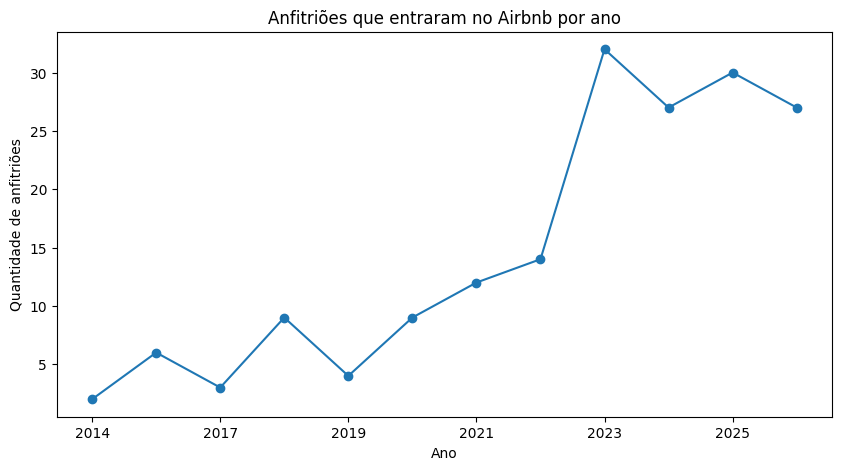

,count
ano,
2014,2
2016,6
2017,3
2018,9
2019,4
2020,9
2021,12
2022,14
2023,32


In [55]:
# Um anfitrião pode ter vários anúncios: drop_duplicates deixa cada anfitrião uma vez só
anfitrioes_por_ano = df.drop_duplicates(subset='anfitriao_id')['ano'].value_counts().sort_index()

anfitrioes_por_ano.plot(figsize=(10, 5), marker='o', title='Anfitriões que entraram no Airbnb por ano')
plt.xlabel('Ano')
plt.ylabel('Quantidade de anfitriões')
plt.show()

anfitrioes_por_ano

### P6. Diária média em reais
Os preços de Albany estão em dólar. A cotação do dólar vem da API do Banco Central (série 1, dólar comercial).

In [56]:
URL_DOLAR = 'https://api.bcb.gov.br/dados/serie/bcdata.sgs.1/dados/ultimos/1?formato=json'

In [57]:
# Requisição para a API do Banco Central para obter a cotação atual do dólar
response = requests.get(URL_DOLAR)
dados_dolar = response.json()

# Extraindo o valor da taxa de venda do dólar comercial
cotacao_dolar = float(dados_dolar[0]['valor'])

# Os preços já estão em dólar: multiplicamos pela cotação para ter o valor em reais
media = df['preco'].mean()
diaria_real = media * cotacao_dolar

print(f"Cotação do Dólar obtida: R$ {cotacao_dolar:.2f}")
print(f"Diária média: US$ {media:.2f}, ou R$ {diaria_real:.2f}")

Cotação do Dólar obtida: R$ 5.33
Diária média: US$ 154.83, ou R$ 825.97


**Leitura:** *(completar com os resultados)*

## 7. Exportação

Salva a base tratada em CSV e em um arquivo de banco de dados SQLite.

In [58]:
# Exportando os dados tratados para formato CSV
df.to_csv('listings_albany_tratado.csv', index=False)

In [59]:
# Salvando a base tratada em um arquivo SQLite (tabela 'listings')
import sqlite3

conexao = sqlite3.connect('airbnb_albany.db')

# O SQLite não guarda listas: salvamos as comodidades como texto
df_sql = df.copy()
df_sql['comodidades'] = df_sql['comodidades'].astype(str)
df_sql.to_sql('listings', conexao, index=False, if_exists='replace')

conexao.close()

## 8. Conclusões

| Pergunta | Resposta |
| --- | --- |
| P1 | |
| P2 | |
| P3 | |
| P4 | |
| P5 | |
| P6 | |

**Limitações:**
- O preço analisado é o anunciado, não o valor pago pelo hóspede.
- Os dados são de uma única extração.
- Albany tem poucos anúncios, então algumas comparações (como a da piscina) têm poucos casos.
- Nesta extração, a data de entrada do anfitrião, as taxas de resposta e aceitação e a reserva imediata vieram vazias. Por isso o ano de entrada (P5) foi estimado pela primeira avaliação.